# All frames, tag 1 basis: tags 2, 3, 4, 5, 12, 11 vs CAD

The first-frame comparison repeated over every frame of one camera, with no rigid body. In each frame tag 1 and the other tags are posed independently (IPPE on the undistorted corners), then re-expressed in tag 1's basis,

    t_1N = R_1.T @ (t_N - t_1)        R_1N = R_1.T @ R_N

and compared with the hardcoded CAD offsets and orientations, which live in tag 1's frame. Nothing is fitted or aligned. Each frame in which tag 1 and tag N are both detected gives one error sample for tag N; the box plots show how those samples are distributed.

CAD only fixes each facet normal, not the in-plane roll. The roll of tags 11 and 12 (135 and 90 degrees about the tag's own z) is taken from the solved rigid body, not from CAD.

In [1]:
# Imports
from pathlib import Path
import pickle

import cv2
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.spatial.transform import Rotation
import toml
from tqdm.auto import tqdm

In [2]:
# Settings
try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:  # running cell-by-cell in an interactive kernel
    NOTEBOOK_DIR = Path.cwd()
    if NOTEBOOK_DIR.name != "jitter_model":
        NOTEBOOK_DIR = NOTEBOOK_DIR / "jitter_model"
PROJECT_ROOT = NOTEBOOK_DIR.parent
RECORDING_DIR = PROJECT_ROOT / "data" / "dome" / "sep18_26" / "dome_rb_def"
DETECTION_CACHE = RECORDING_DIR / "jitter_detections.pkl"
CALIBRATION_TOML = (
    PROJECT_ROOT
    / "data"
    / "calibration"
    / "dual_160"
    / "calib_radxa_sep18_26"
    / "stereo_calibration.toml"
)

CAMERA = "cam0"
TAG_SIZE_M = 0.05
REFERENCE_ID = 1
EULER_ORDER = "xyz"
MM = 1000.0
# None keeps every pose. Set e.g. 1.5 to drop tags whose IPPE fit is poor.
MAX_REPROJ_PX = None

# CAD, in tag 1's frame: tag centre offset (x, y, z) in mm, and orientation as
# xyz Euler angles in degrees.
CAD_OFFSET_MM = {
    2: (56.61, 0.0, -15.17),
    5: (0.0, 56.61, -15.17),
    3: (-56.61, 0.0, -15.17),
    4: (0.0, -56.61, -15.17),
    12: (-98.058, 0.0, -56.61),
    11: (-64.146, -64.146, -56.61),
}
CAD_EULER_DEG = {
    2: (0.0, 30.0, 0.0),
    5: (-30.0, 0.0, 0.0),
    3: (0.0, -30.0, 0.0),
    4: (30.0, 0.0, 0.0),
    12: (-60.0, 0.0, 90.0),
    11: (-67.792, 0.0, 135.0),
}
RING_IDS = (2, 3, 4, 5, 12, 11)

TAG_CORNERS = np.asarray(
    [
        [-TAG_SIZE_M / 2, +TAG_SIZE_M / 2, 0.0],
        [+TAG_SIZE_M / 2, +TAG_SIZE_M / 2, 0.0],
        [+TAG_SIZE_M / 2, -TAG_SIZE_M / 2, 0.0],
        [-TAG_SIZE_M / 2, -TAG_SIZE_M / 2, 0.0],
    ],
    dtype=np.float64,
)

In [3]:
# Measure
def estimate_marker_pose(corners, K, D):
    """Lowest-reprojection-error positive-depth IPPE pose of one square tag."""
    undistorted = cv2.fisheye.undistortPoints(
        np.asarray(corners, dtype=np.float64).reshape(-1, 1, 2), K, D, P=K
    ).reshape(4, 2)
    ok, rvecs, tvecs, _err = cv2.solvePnPGeneric(
        TAG_CORNERS, undistorted, K, None, flags=cv2.SOLVEPNP_IPPE_SQUARE
    )
    best = None
    for rvec, tvec in zip(rvecs, tvecs):
        tvec = np.asarray(tvec, dtype=np.float64).reshape(3)
        if tvec[2] <= 0:
            continue
        projected, _ = cv2.projectPoints(TAG_CORNERS, rvec, tvec, K, None)
        rmse = float(
            np.sqrt(np.mean(np.sum((projected.reshape(4, 2) - undistorted) ** 2, axis=1)))
        )
        if best is None or rmse < best[2]:
            best = (cv2.Rodrigues(rvec)[0], tvec, rmse)
    return best


def usable(pose):
    return pose is not None and (MAX_REPROJ_PX is None or pose[2] <= MAX_REPROJ_PX)


calibration = toml.load(CALIBRATION_TOML)[CAMERA]
K = np.asarray(calibration["camera_matrix"], dtype=np.float64)
D = np.asarray(calibration["dist_coeffs"], dtype=np.float64).reshape(-1, 1)

with DETECTION_CACHE.open("rb") as stream:
    all_detections = pickle.load(stream)["cameras"][CAMERA]["detections"]  # noqa: S301
print(f"{CAMERA}: {len(all_detections)} frames")

cam0: 1005 frames


In [4]:
# Error vs CAD for every frame where tag 1 and tag N are both detected
CAD_ROTATION = {
    marker_id: Rotation.from_euler(EULER_ORDER, euler, degrees=True)
    for marker_id, euler in CAD_EULER_DEG.items()
}

rows = []
for frame_index, frame in enumerate(tqdm(all_detections, desc=f"{CAMERA} frames")):
    if REFERENCE_ID not in frame:
        continue
    reference = estimate_marker_pose(frame[REFERENCE_ID], K, D)
    if not usable(reference):
        continue
    R_ref, t_ref, _ = reference

    for marker_id in RING_IDS:
        if marker_id not in frame:
            continue
        pose = estimate_marker_pose(frame[marker_id], K, D)
        if not usable(pose):
            continue
        R_meas, t_meas, reproj_px = pose

        cad_vector = np.asarray(CAD_OFFSET_MM[marker_id]) / MM
        position_error = R_ref.T @ (t_meas - t_ref) - cad_vector

        measured_rel = Rotation.from_matrix(R_ref.T @ R_meas)
        error = CAD_ROTATION[marker_id].inv() * measured_rel
        err_e = error.as_euler(EULER_ORDER, degrees=True)

        rows.append(
            {
                "frame": frame_index,
                "tag": marker_id,
                "err_x": MM * position_error[0],
                "err_y": MM * position_error[1],
                "err_z": MM * position_error[2],
                "err_norm": MM * float(np.linalg.norm(position_error)),
                "err_rx": err_e[0],
                "err_ry": err_e[1],
                "err_rz": err_e[2],
                "err_angle": float(np.degrees(error.magnitude())),
                "reproj_px": reproj_px,
            }
        )

errors = pl.DataFrame(rows)
print(f"{errors.height} samples")

cam0 frames:   0%|          | 0/1005 [00:00<?, ?it/s]

3109 samples


In [5]:
# Summary per tag: frames used, median and inter-quartile range
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_tbl_rows(50)
pl.Config.set_tbl_cols(30)
pl.Config.set_float_precision(3)

columns = ["err_x", "err_y", "err_z", "err_norm", "err_rx", "err_ry", "err_rz", "err_angle"]
aggregations = [pl.len().alias("n_frames")]
for column in columns:
    aggregations.append(pl.col(column).median().alias(f"{column}_med"))
    aggregations.append(
        (pl.col(column).quantile(0.75) - pl.col(column).quantile(0.25)).alias(f"{column}_iqr")
    )
summary = (
    errors.group_by("tag")
    .agg(aggregations)
    .with_columns(order=pl.col("tag").replace_strict({t: i for i, t in enumerate(RING_IDS)}))
    .sort("order")
    .drop("order")
)
summary.select("tag", "n_frames", *[c for c in summary.columns if c.startswith("err_") and c.endswith("_med")])

tag,n_frames,err_x_med,err_y_med,err_z_med,err_norm_med,err_rx_med,err_ry_med,err_rz_med,err_angle_med
i64,u32,f64,f64,f64,f64,f64,f64,f64,f64
2,567,4.426,0.951,-7.848,12.896,-2.331,-4.361,-0.243,5.272
3,553,0.139,-0.260,-0.647,1.343,-0.248,-0.614,0.317,1.162
4,539,0.201,-0.270,0.467,0.917,-0.972,-0.177,-0.021,1.412
5,551,1.139,0.895,-6.728,7.875,-0.169,-0.761,0.241,1.497
12,492,0.069,-0.446,-8.189,9.566,0.352,0.385,0.714,1.706
11,407,0.085,-1.369,-0.481,5.473,0.895,0.127,0.076,1.607


In [6]:
# Spread: inter-quartile range per tag
summary.select("tag", *[c for c in summary.columns if c.endswith("_iqr")])

tag,err_x_iqr,err_y_iqr,err_z_iqr,err_norm_iqr,err_rx_iqr,err_ry_iqr,err_rz_iqr,err_angle_iqr
i64,f64,f64,f64,f64,f64,f64,f64,f64
2,3.880,0.628,13.911,10.746,1.994,6.054,1.204,5.192
3,1.517,0.213,1.618,3.450,0.878,1.061,0.417,1.185
4,1.423,0.957,2.391,5.073,0.893,1.179,0.514,1.218
5,2.209,2.479,6.710,5.635,1.725,1.422,0.610,1.905
12,1.441,0.934,8.330,7.959,1.927,1.108,0.913,1.403
11,1.983,0.599,10.771,6.253,2.101,1.211,1.379,1.977


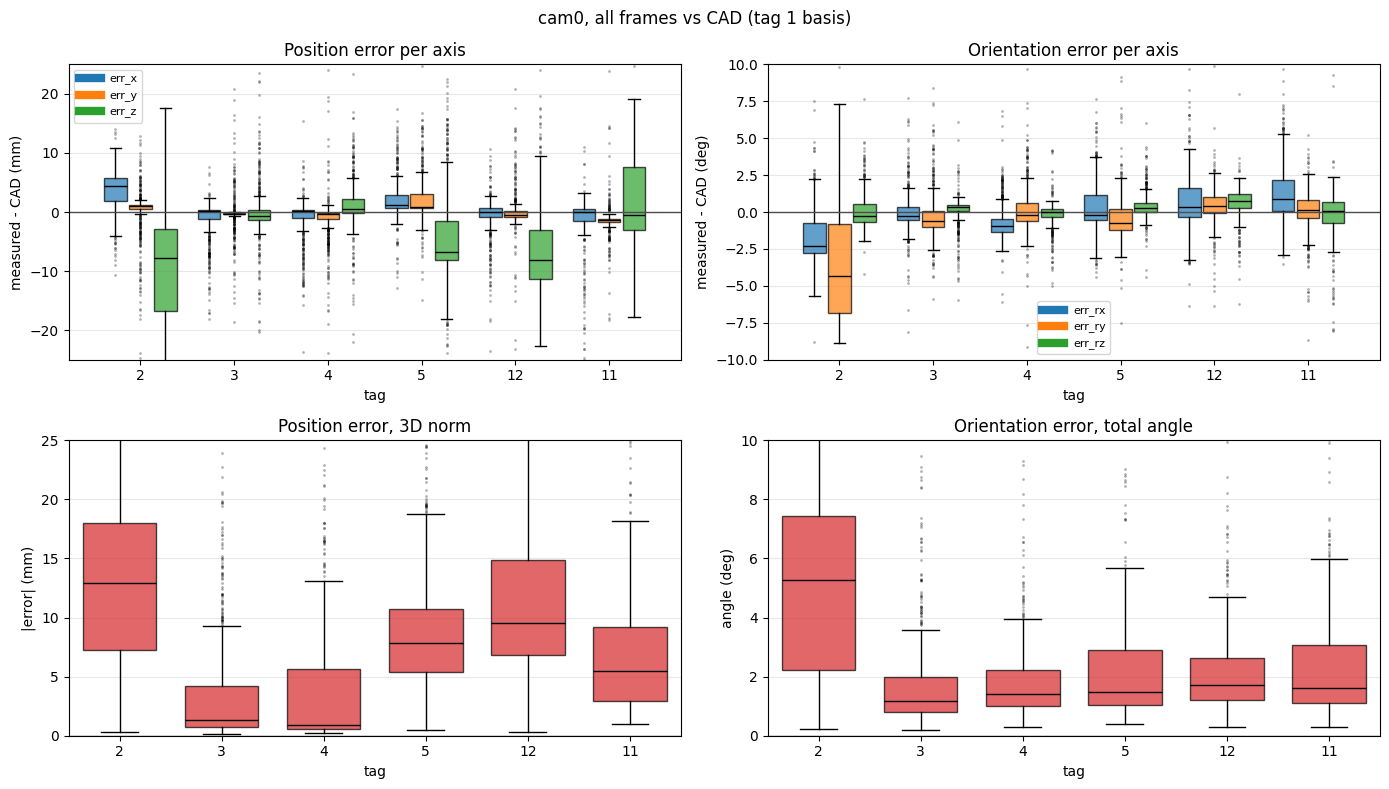

In [9]:
# Box plots of the per-frame error vs CAD, in tag 1's basis
POSITION_LIMIT_MM = 25.0
ORIENTATION_LIMIT_DEG = 10.0


def grouped_boxplot(axis, group_columns, colors, title, ylabel, ylim):
    n_groups = len(group_columns)
    width = 0.8 / n_groups
    for index, (column, color) in enumerate(zip(group_columns, colors)):
        data = [errors.filter(pl.col("tag") == t)[column].to_numpy() for t in RING_IDS]
        positions = np.arange(len(RING_IDS)) + (index - (n_groups - 1) / 2) * width
        artists = axis.boxplot(
            data,
            positions=positions,
            widths=width * 0.9,
            patch_artist=True,
            flierprops={"marker": ".", "markersize": 2, "alpha": 0.3},
            medianprops={"color": "k"},
        )
        for box in artists["boxes"]:
            box.set_facecolor(color)
            box.set_alpha(0.7)
    axis.set_ylim(*ylim)
    axis.axhline(0, color="0.3", linewidth=1)
    axis.set_xticks(np.arange(len(RING_IDS)), [str(t) for t in RING_IDS])
    axis.set_xlabel("tag")
    axis.set_ylabel(ylabel)
    axis.set_title(title)
    axis.grid(axis="y", alpha=0.3)
    if n_groups > 1:
        axis.legend(
            handles=[
                plt.Line2D([], [], color=color, linewidth=6, label=column)
                for column, color in zip(group_columns, colors)
            ],
            fontsize=8,
        )


figure, axes = plt.subplots(2, 2, figsize=(14, 8))
axis_colors = ["tab:blue", "tab:orange", "tab:green"]
grouped_boxplot(axes[0, 0], ["err_x", "err_y", "err_z"], axis_colors,
                "Position error per axis", "measured - CAD (mm)",
                (-POSITION_LIMIT_MM, POSITION_LIMIT_MM))
grouped_boxplot(axes[0, 1], ["err_rx", "err_ry", "err_rz"], axis_colors,
                "Orientation error per axis", "measured - CAD (deg)",
                (-ORIENTATION_LIMIT_DEG, ORIENTATION_LIMIT_DEG))
grouped_boxplot(axes[1, 0], ["err_norm"], ["tab:red"],
                "Position error, 3D norm", "|error| (mm)",
                (0.0, POSITION_LIMIT_MM))
grouped_boxplot(axes[1, 1], ["err_angle"], ["tab:red"],
                "Orientation error, total angle", "angle (deg)",
                (0.0, ORIENTATION_LIMIT_DEG))
figure.suptitle(f"{CAMERA}, all frames vs CAD (tag 1 basis)")
figure.tight_layout()
plt.show()